In [41]:
import pandas as pd
from requests import head
import numpy as np

df_validation = pd.read_csv("outputs/VALIDATION_FD001.csv")
df_fitting = pd.read_csv("outputs/FITTING_FD001.csv")

df_fitting.head()

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191.0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190.0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189.0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188.0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187.0


In [42]:
fitting_X = df_fitting.drop(columns=df_fitting.columns[[0, -1]])
fitting_Y = df_fitting.iloc[:, -1]

validation_X = df_validation.drop(columns=df_validation.columns[[0, -1]])
validation_Y = df_validation.iloc[:, -1]

In [43]:
from sklearn.linear_model import LinearRegression

lin_reg_model = LinearRegression()

lin_reg_model.fit(fitting_X, fitting_Y)

rul_predictions = lin_reg_model.predict(validation_X)



To evaluate the performance of the linear regression, we can use MAE (Average absolute error), RMSE (Average square error) and the Mean signed error. Since the last one is SIGNED one positive and one negative error can eliminate each other - its therefore bad in estimating how good the model perfoms in predicting BUT we can estimate wether it tends to predict values to high or to low which can be a valuable information because in the field of high-safety applications like engines we would much rather want our model to predict the RUL LOWER than it actually is.

In [44]:
errors = rul_predictions - validation_Y

mae = np.abs(errors).mean()
print(mae)

rmse = np.sqrt((errors ** 2).mean())
print(rmse)

mean_signed_error = errors.mean()
print(mean_signed_error)

30.23751102876667
37.03377948498099
13.649228922753336


As expected the mean signed error is lower than the other two. It tells us that we tend to OVERESTIMATE the remaining useful lifetime which is not good at all! We are generally off by 30.237 cycles... Which i am not to happy about that feels like a lot.

In [45]:
errors_fitting = lin_reg_model.predict(fitting_X) - fitting_Y

mae = np.abs(errors_fitting).mean()
print(mae)

rmse = np.sqrt((errors_fitting ** 2).mean())
print(rmse)

mean_signed_error = errors_fitting.mean()
print(mean_signed_error)

31.670451150558627
41.30980197409274
1.159494380279619e-11


What i find super interesting is that on the FITTING data that was used to train the model - it performs WORSE than on the validation data. This is very untypical but could be due to more extream engine sensor measurements in the fitting set.

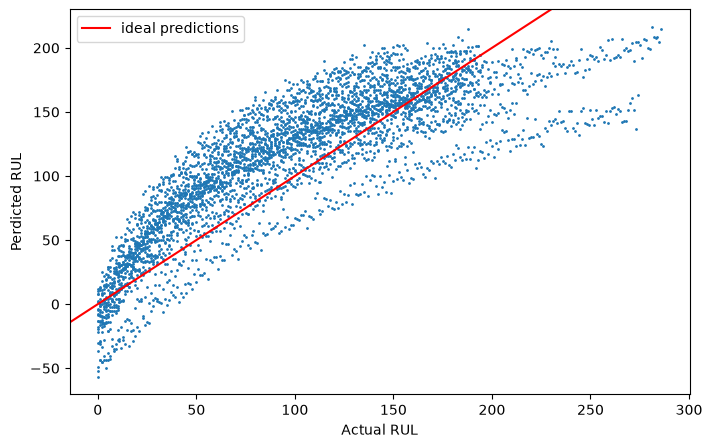

In [46]:
import matplotlib.pyplot as plt

fig, err_plt = plt.subplots(figsize = (8, 5))
err_plt.scatter(validation_Y, rul_predictions, s=1)
err_plt.axline((0, 0), slope=1, color = "red", label = "ideal predictions")
err_plt.set_xlabel("Actual RUL")
err_plt.set_ylabel("Perdicted RUL")
err_plt.legend()

Now first we will see if the kNN regressor will perform better:

In [47]:
from sklearn.neighbors import KNeighborsRegressor
knn_model = KNeighborsRegressor(n_neighbors=40)

knn_model.fit(fitting_X, fitting_Y)
knn_predictions = knn_model.predict(validation_X)

knn_error = knn_predictions - validation_Y 

mae = np.abs(knn_error).mean()
print(mae)

rmse = np.sqrt((knn_error ** 2).mean())
print(rmse)

mean_signed_error = knn_error.mean()
print(mean_signed_error)

28.353477757778347
35.36734375213985
14.801986371817948


The results are not noticably better than on the linear regression but I forgot to normalize the data so this is a great chance to see how much normalization affects the performance of this model!

In [48]:
from sklearn import preprocessing

scaler = preprocessing.StandardScaler()

scaler.fit(fitting_X)
scaled_fitting_X = scaler.transform(fitting_X)
scaled_validation_X = scaler.transform(validation_X)

knn_model_scaled = KNeighborsRegressor(n_neighbors=15)

knn_model_scaled.fit(scaled_fitting_X, fitting_Y)
knn_predictions = knn_model_scaled.predict(scaled_validation_X)

knn_error = knn_predictions - validation_Y 

mae = np.abs(knn_error).mean()
print(mae)

rmse = np.sqrt((knn_error ** 2).mean())
print(rmse)

mean_signed_error = knn_error.mean()
print(mean_signed_error)

27.99369160881118
36.62927081545559
12.36067540927402


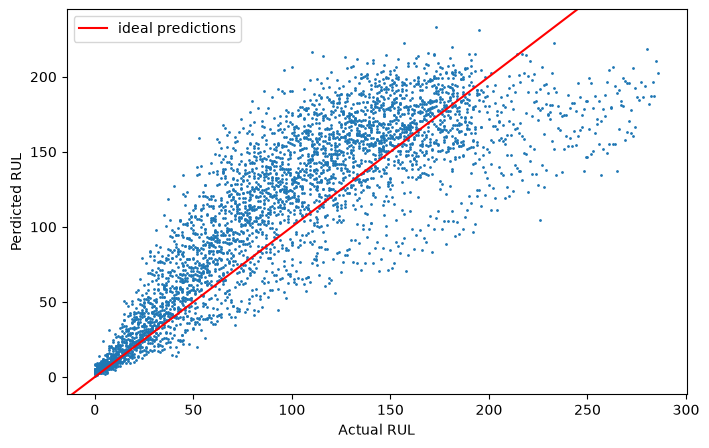

In [49]:
fig, err_plt = plt.subplots(figsize = (8, 5))
err_plt.scatter(validation_Y, knn_predictions, s=1)
err_plt.axline((0, 0), slope=1, color = "red", label = "ideal predictions")
err_plt.set_xlabel("Actual RUL")
err_plt.set_ylabel("Perdicted RUL")
err_plt.legend()

The results are slightly better on the scaled model.

Now the DecisionTreeRegressor:

In [50]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=3)

tree_model.fit(fitting_X, fitting_Y)
tree_predictions = tree_model.predict(validation_X)

tree_error = tree_predictions - validation_Y 

mae = np.abs(tree_error).mean()
print(mae)

rmse = np.sqrt((tree_error ** 2).mean())
print(rmse)

mean_signed_error = tree_error.mean()
print(mean_signed_error)

28.802540544366053
35.989902854530925
12.402751542176834
